# P6 – Scoring crédit « Prêt à dépenser »
## Notebook 02 : modélisation, coût métier et seuil de décision

**Démarche**
1. Découper les données en **train / validation / test** (70 / 15 / 15, stratifié).
2. Entraîner un **LightGBM** (early stopping sur la validation, métrique AUC).
3. Définir un **coût métier** : accorder un crédit à un futur défaillant (FN) coûte
   bien plus cher que refuser un bon client (FP).
4. Choisir le **seuil** qui minimise ce coût sur la validation, puis le juger
   sur le **test** (jamais utilisé pour choisir quoi que ce soit).
5. Sauvegarder le modèle et ses métadonnées pour l'API et le dashboard.

**Choix éthique** : `CODE_GENDER` est **exclue** du modèle. Elle apparaissait dans le top 5
des variables, mais utiliser le genre pour décider d'un crédit est discriminatoire (et illégal
dans de nombreuses juridictions). Le coût en performance est négligeable.

**Choix important** : pas de `is_unbalance` ni de `scale_pos_weight`. Ils améliorent
parfois l'AUC mais **déforment les probabilités**. Or le dashboard doit afficher un score
interprétable par un chargé de relation client. On garde des probabilités fiables et on
traite le déséquilibre avec le **seuil de décision**.

In [1]:
import gc
import json
import os
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

RAW_DIR = Path(
    os.environ.get(
        "P6_DATA_DIR",
        r"D:\Python_Datascience\Projet_OC6\Projet+Mise+en+prod+-+home-credit-default-risk",
    )
)
PROCESSED_DIR = RAW_DIR / "processed"
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

SEED = 42
COUT_FN = 10  # crédit accordé à un client qui fera défaut
COUT_FP = 1  # bon client refusé (manque à gagner)
MAX_ROUNDS = int(os.environ.get("P6_MAX_ROUNDS", 3000))

# Variable discriminatoire : le genre ne doit pas intervenir dans une décision de crédit
EXCLUDED = ["CODE_GENDER"]

### 1. Chargement et découpage

In [2]:
data = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")
y = data.pop("TARGET").astype(np.int8)
data.drop(columns=EXCLUDED, inplace=True)  # variables sensibles : exclues du modèle
X = data
print("X :", X.shape, X.dtypes.unique(), f"| {X.memory_usage().sum() / 1e6:.0f} Mo")
print(f"Taux de défaut : {y.mean():.4f}")

X : (307507, 793) [dtype('float32')] | 977 Mo
Taux de défaut : 0.0807


In [3]:
idx = np.arange(len(X))
idx_train, idx_rest = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_valid, idx_test = train_test_split(
    idx_rest, test_size=0.50, stratify=y.iloc[idx_rest], random_state=SEED
)

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_valid, y_valid = X.iloc[idx_valid], y.iloc[idx_valid]
X_test, y_test = X.iloc[idx_test], y.iloc[idx_test]
feature_names = list(X.columns)

del X, data
gc.collect()

for name, part in (("train", y_train), ("valid", y_valid), ("test", y_test)):
    print(f"{name:6s} {len(part):7d} lignes | taux de défaut {part.mean():.4f}")

train   215254 lignes | taux de défaut 0.0807
valid    46126 lignes | taux de défaut 0.0807
test     46127 lignes | taux de défaut 0.0807


### 2. Entraînement LightGBM

- `learning_rate = 0.05` : compromis vitesse / précision (le kernel original utilise 0.02,
  trois fois plus lent pour un gain négligeable).
- `feature_fraction = 0.5` et `max_bin = 63` : réduisent le temps et la mémoire.
- Early stopping sur l'**AUC de validation** (100 arbres de patience).

⏱ Compter **10 à 20 minutes** sur un portable 8 Go.

In [4]:
PARAMS = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.05,
    "num_leaves": 34,
    "max_depth": 8,
    "feature_fraction": 0.5,
    "bagging_fraction": 0.87,
    "bagging_freq": 1,
    "lambda_l1": 0.04,
    "lambda_l2": 0.07,
    "min_split_gain": 0.02,
    "min_sum_hessian_in_leaf": 39.0,
    "max_bin": 63,
    "seed": SEED,
    "verbose": -1,
}

dtrain = lgb.Dataset(X_train, label=y_train)
dvalid = lgb.Dataset(X_valid, label=y_valid, reference=dtrain)

t0 = time.time()
model = lgb.train(
    PARAMS,
    dtrain,
    num_boost_round=MAX_ROUNDS,
    valid_sets=[dvalid],
    valid_names=["valid"],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(50)],
)
print(f"\nArbres retenus : {model.best_iteration} | durée {time.time() - t0:.0f} s")

Training until validation scores don't improve for 100 rounds
[50]	valid's auc: 0.763929
[100]	valid's auc: 0.774514
[150]	valid's auc: 0.779887
[200]	valid's auc: 0.782076
[250]	valid's auc: 0.783744
[300]	valid's auc: 0.78464
[350]	valid's auc: 0.785264
[400]	valid's auc: 0.785288
[450]	valid's auc: 0.785227
Early stopping, best iteration is:
[378]	valid's auc: 0.785419

Arbres retenus : 378 | durée 94 s


In [5]:
proba_valid = model.predict(X_valid, num_iteration=model.best_iteration)
proba_test = model.predict(X_test, num_iteration=model.best_iteration)
auc_valid = roc_auc_score(y_valid, proba_valid)
auc_test = roc_auc_score(y_test, proba_test)
print(f"AUC validation : {auc_valid:.4f}")
print(f"AUC test       : {auc_test:.4f}")

AUC validation : 0.7854
AUC test       : 0.7903


### 3. Coût métier et seuil de décision

Un client est **refusé** si sa probabilité de défaut est **≥ seuil**.

$$\text{Coût} = c_{FN} \times \#\text{défauts acceptés} + c_{FP} \times \#\text{bons clients refusés}$$

Avec des probabilités bien calibrées, le seuil optimal théorique est
$p^* = c_{FP} / (c_{FP} + c_{FN})$. On le compare au seuil trouvé empiriquement.

In [6]:
def business_cost(y_true, proba, threshold, c_fn=COUT_FN, c_fp=COUT_FP):
    """Coût métier total pour un seuil donné (refus si proba >= seuil)."""
    y_true = np.asarray(y_true)
    refused = np.asarray(proba) >= threshold
    false_neg = np.sum(~refused & (y_true == 1))
    false_pos = np.sum(refused & (y_true == 0))
    return c_fn * false_neg + c_fp * false_pos


thresholds = np.round(np.arange(0.01, 0.80, 0.01), 2)
costs_valid = np.array([business_cost(y_valid, proba_valid, t) for t in thresholds])
best_threshold = float(thresholds[costs_valid.argmin()])
theoretical = COUT_FP / (COUT_FP + COUT_FN)
print(f"Seuil optimal (validation) : {best_threshold:.2f}")
print(f"Seuil théorique            : {theoretical:.3f}")

Seuil optimal (validation) : 0.09
Seuil théorique            : 0.091


In [7]:
def decision_report(y_true, proba, threshold):
    """Indicateurs de décision au seuil choisi, avec comparaison à « tout accepter »."""
    y_true = np.asarray(y_true)
    refused = np.asarray(proba) >= threshold
    cost = business_cost(y_true, proba, threshold)
    baseline = COUT_FN * y_true.sum()  # on accorde tous les crédits
    return {
        "seuil": threshold,
        "taux_de_refus": refused.mean(),
        "defauts_detectes": (refused & (y_true == 1)).sum() / y_true.sum(),
        "bons_clients_refuses": (refused & (y_true == 0)).sum() / (y_true == 0).sum(),
        "cout": float(cost),
        "cout_si_tout_accepter": float(baseline),
        "gain_vs_tout_accepter": 1 - cost / baseline,
    }


report_valid = decision_report(y_valid, proba_valid, best_threshold)
report_test = decision_report(y_test, proba_test, best_threshold)
print(pd.DataFrame({"validation": report_valid, "test": report_test}).round(4))

                       validation        test
seuil                      0.0900      0.0900
taux_de_refus              0.2681      0.2750
defauts_detectes           0.6568      0.6724
bons_clients_refuses       0.2340      0.2401
cout                   22700.0000  22380.0000
cout_si_tout_accepter  37240.0000  37240.0000
gain_vs_tout_accepter      0.3904      0.3990


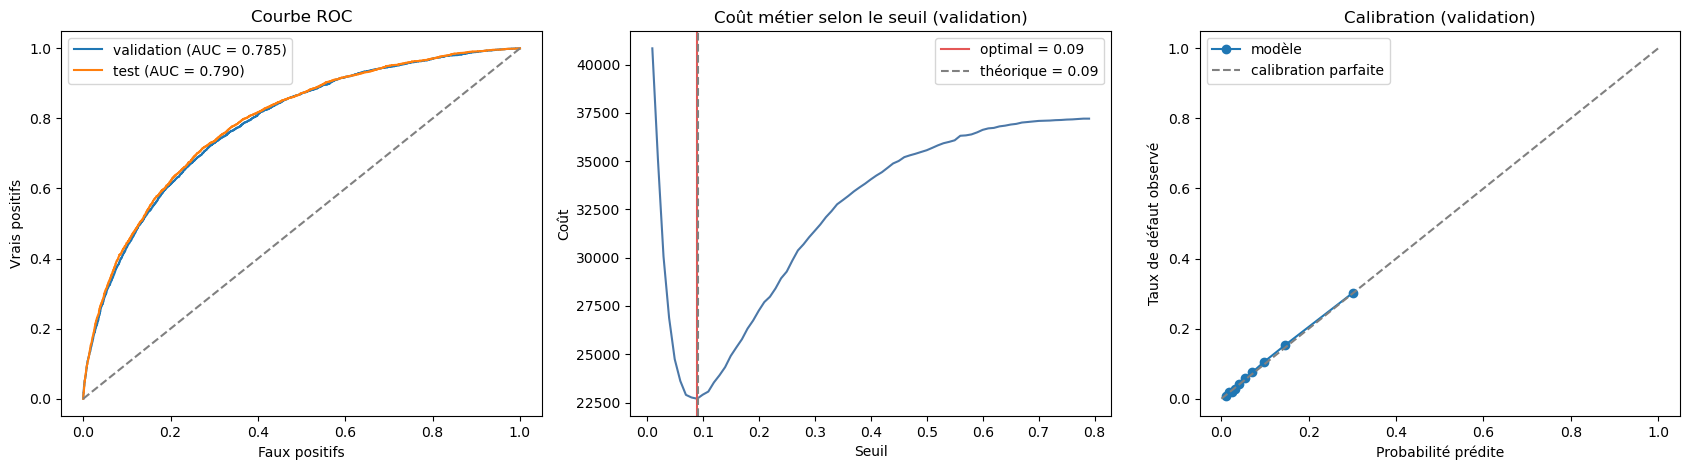

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for label, y_true, proba in (("validation", y_valid, proba_valid), ("test", y_test, proba_test)):
    fpr, tpr, _ = roc_curve(y_true, proba)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_true, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(title="Courbe ROC", xlabel="Faux positifs", ylabel="Vrais positifs")
axes[0].legend()

axes[1].plot(thresholds, costs_valid, color="#4C78A8")
axes[1].axvline(best_threshold, color="#E45756", label=f"optimal = {best_threshold:.2f}")
axes[1].axvline(theoretical, color="grey", ls="--", label=f"théorique = {theoretical:.2f}")
axes[1].set(title="Coût métier selon le seuil (validation)", xlabel="Seuil", ylabel="Coût")
axes[1].legend()

frac_pos, mean_pred = calibration_curve(y_valid, proba_valid, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, "o-", label="modèle")
axes[2].plot([0, 1], [0, 1], "--", color="grey", label="calibration parfaite")
axes[2].set(title="Calibration (validation)", xlabel="Probabilité prédite",
            ylabel="Taux de défaut observé")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "P6_02_evaluation_modele.png", dpi=150)
plt.show()

### 4. Variables les plus importantes

Importance « gain » : contribution cumulée de chaque variable à la réduction de l'erreur.
L'interprétabilité fine (SHAP, globale et locale) fera l'objet de l'étape suivante.

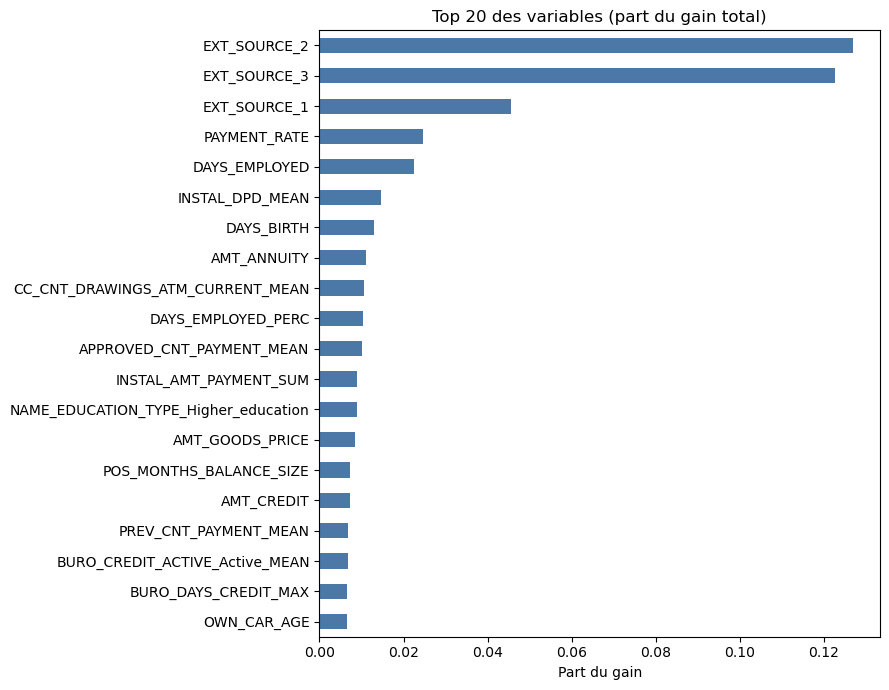

Variables réellement utilisées : 535 / 793


In [9]:
importance = pd.Series(
    model.feature_importance(importance_type="gain"), index=feature_names
).sort_values(ascending=False)
importance = importance / importance.sum()

fig, ax = plt.subplots(figsize=(9, 7))
importance.head(20)[::-1].plot.barh(ax=ax, color="#4C78A8")
ax.set(title="Top 20 des variables (part du gain total)", xlabel="Part du gain")
plt.tight_layout()
plt.savefig(FIG_DIR / "P6_02_importance_variables.png", dpi=150)
plt.show()
print(f"Variables réellement utilisées : {(importance > 0).sum()} / {len(importance)}")

### 5. Sauvegarde du modèle et des métadonnées

In [10]:
model_path = MODEL_DIR / "lgbm_model.txt"
model.save_model(model_path, num_iteration=model.best_iteration)

metadata = {
    "seuil_decision": best_threshold,
    "seuil_theorique": theoretical,
    "cout_fn": COUT_FN,
    "cout_fp": COUT_FP,
    "auc_validation": round(float(auc_valid), 5),
    "auc_test": round(float(auc_test), 5),
    "arbres": int(model.best_iteration),
    "params": PARAMS,
    "variables": feature_names,
    "variables_exclues": EXCLUDED,
    "rapport_test": {k: float(v) for k, v in report_test.items()},
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
importance.rename("part_du_gain").to_csv(MODEL_DIR / "feature_importance.csv")

# Contrôle : le modèle rechargé donne exactement les mêmes probabilités
reloaded = lgb.Booster(model_file=str(model_path))
assert np.allclose(reloaded.predict(X_test), proba_test)
print("Modèle sauvegardé et vérifié :", model_path.resolve())
print(f"Taille : {model_path.stat().st_size / 1e6:.1f} Mo")

Modèle sauvegardé et vérifié : C:\Users\PC\Documents\data_project6\models\lgbm_model.txt
Taille : 1.5 Mo


### Synthèse

Les chiffres définitifs (AUC test, seuil, gain de coût) sont ceux affichés ci-dessus et
sauvegardés dans `models/metadata.json`.

**Prochaine étape** : optimisation des hyperparamètres, puis interprétabilité (SHAP),
API FastAPI et dashboard Streamlit.